# Auxiliary (Ancilla) Qubit Operations — Controlled Operations via Compute/Uncompute
### Qiskit notebook — matched against the CUDA-Q version of this notebook

**Chapter / concept:** Auxiliary Operations — using an ancilla qubit to implement a
multi-controlled operation with only 2-qubit and 3-qubit *controlled* gates (Toffoli /
CNOT), then returning the ancilla to a clean `|0>` state ("compute–uncompute").

**Circuit implemented:**
1. `H(q0)`, `H(q1)` — put both control qubits into equal superposition so all 4
   control combinations are exercised simultaneously (state prep only, not a controlled op).
2. `CCX(q0, q1 -> q2)` — Toffoli: **compute** the logical AND of the two controls into
   the ancilla qubit `q2` (starts at `|0>`).
3. `CX(q2 -> q3)` — CNOT: apply the controlled operation on the **target** `q3`, using the
   ancilla as the (single) control. Because `q2` only became `1` when *both* `q0` and `q1`
   were `1`, this line is effectively "flip `q3` iff `q0=q1=1`".
4. `CCX(q0, q1 -> q2)` — Toffoli again: **uncompute** the ancilla, restoring it to `|0>`
   with no leftover entanglement, so it is a "clean" qubit usable by later parts of a
   larger circuit.

Net effect on `(q0, q1, q3)`: identical to a direct Toffoli `CCX(q0, q1 -> q3)`, but built
entirely out of controlled gates plus one reusable ancilla — this is the standard trick for
building/relaying multi-controlled operations without a native multi-controlled gate.

### GLOBAL SETUP (identical in both notebooks — do not diverge)
- **N QUBITS:** 4  →  `q0`, `q1` = controls, `q2` = ancilla/auxiliary, `q3` = target
- **Gate sequence:** `H(q0)`, `H(q1)`, `CCX(q0,q1->q2)`, `CX(q2->q3)`, `CCX(q0,q1->q2)`
- **QUBIT ORDERING CONTRACT:** qubit 0 = **rightmost** bit in every printed bitstring
  (Qiskit's native convention — no reversal needed in this notebook; the CUDA-Q notebook
  performs an explicit reversal to match this).
- **SHOTS:** 10000, **SEED:** 42
- **GLOBAL PHASE CONVENTION:** normalize so the first amplitude with `|amp| > 1e-9`, taken
  in ascending bitstring order, is rotated to be real and positive
  (`phase = angle(amp)`, multiply the whole vector by `exp(-1j*phase)`).
- **Basis ordering for matrices:** `{|0000>, |0001>, ..., |1111>}`, ascending binary order.

### Theory recap
- `H = 1/sqrt(2) * [[1, 1], [1, -1]]`
- `X = [[0, 1], [1, 0]]`
- `CCX` (Toffoli) truth table: target flips **iff** both controls are `1`, identity otherwise.
- `CX` (CNOT) truth table: target flips **iff** the control is `1`, identity otherwise.
- Because `H`, `X`, `CCX`, `CX` are all real-valued (permutation/real-orthogonal) matrices,
  every reachable amplitude in this circuit is real — so the phase-normalization step below
  is expected to be a **no-op** here (included anyway for generality/reusability).

**Ordering-convention warning:** none for this notebook — see the ordering-fix markdown
cell below for the explicit statement.

**Run all cells top to bottom.** This circuit uses only 4 qubits (16-dim statevector,
a few hundred bytes) — it is extremely lightweight and will run instantly on Colab's free
CPU runtime or on a low-RAM laptop; no GPU is needed.


In [1]:
# Install Qiskit + Aer + the LaTeX-label renderer used by circuit.draw(output="mpl")
# qiskit-aer ships separately from qiskit (it is the high-performance simulator backend).
# pylatexenc renders the gate-label boxes for the matplotlib circuit drawer.
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 33.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.0 MB/s eta 0:00:00


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator

# ---- GLOBAL SETUP (must match the CUDA-Q notebook exactly) ----
N_QUBITS = 4      # q0, q1 = controls | q2 = ancilla (auxiliary) | q3 = target
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "aux_ops_ccx_ancilla"

print("N_QUBITS:", N_QUBITS)
print("SHOTS:", SHOTS)
print("SEED:", SEED)


N_QUBITS: 4
SHOTS: 10000
SEED: 42


In [3]:
# Build the circuit gate-by-gate.
qc = QuantumCircuit(N_QUBITS, name="aux_ops_ccx_ancilla")

# q0, q1 = control qubits | q2 = ancilla (auxiliary) qubit | q3 = target qubit
Q0, Q1, Q2_ANCILLA, Q3_TARGET = 0, 1, 2, 3

# 1) Put both controls into equal superposition so all 4 control combinations
#    (00, 01, 10, 11) are exercised in a single run -- this is state prep, not a
#    controlled operation, and lets us sanity-check the ancilla trick against all inputs
#    at once instead of running the circuit 4 separate times.
qc.h(Q0)
qc.h(Q1)

# 2) COMPUTE: Toffoli (CCX) writes AND(q0, q1) into the ancilla q2 (which starts at |0>).
#    q2 becomes |1> only on the branch where q0=1 AND q1=1.
qc.ccx(Q0, Q1, Q2_ANCILLA)

# 3) APPLY: use the ancilla as a *single* control for a CNOT onto the target q3.
#    Since q2 only equals 1 exactly when both original controls were 1, this line
#    implements a controlled operation on q3 that is jointly controlled by q0 AND q1,
#    even though the physical gate used here is only a 2-qubit CX.
qc.cx(Q2_ANCILLA, Q3_TARGET)

# 4) UNCOMPUTE: apply the same Toffoli again. Toffoli is its own inverse, so this
#    resets the ancilla q2 back to a clean |0>, disentangled from the rest of the
#    register and ready to be reused elsewhere in a larger circuit.
qc.ccx(Q0, Q1, Q2_ANCILLA)

print(qc.draw(output="text"))


     ┌───┐               
q_0: ┤ H ├──■─────────■──
     ├───┤  │         │  
q_1: ┤ H ├──■─────────■──
     └───┘┌─┴─┐     ┌─┴─┐
q_2: ─────┤ X ├──■──┤ X ├
          └───┘┌─┴─┐└───┘
q_3: ──────────┤ X ├─────
               └───┘     


/usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/matplotlib.py:273: UserWarning: Style JSON file 'default.json' not found in any of these locations: /usr/local/lib/python3.12/dist-packages/qiskit/visualization/circuit/styles/default.json, default.json. Will use default style.
  self._style, def_font_ratio = load_style(


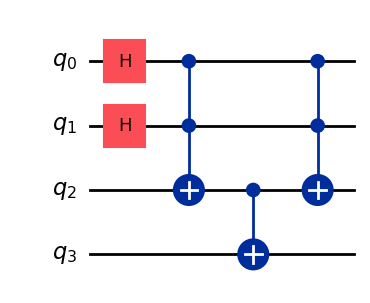

In [4]:
# Draw the circuit with matplotlib and save it to disk.
fig = qc.draw(output="mpl", style={"name": "default"})
fig.savefig("aux_ops_ccx_ancilla_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# --- Individual gate matrices (basis: {|0>, |1>}) ---
H_gate = (1 / np.sqrt(2)) * np.array([[1, 1], [1, -1]], dtype=complex)
X_gate = np.array([[0, 1], [1, 0]], dtype=complex)
print("H =\n", np.round(H_gate, 4))
print("X =\n", np.round(X_gate, 4))

# --- Manual full-circuit unitary, built by hand in NumPy using Qiskit's own bit
#     convention (qubit 0 = least-significant / rightmost tensor factor), so this
#     independently cross-checks qiskit.quantum_info.Operator(qc) below. ---
I2 = np.eye(2, dtype=complex)
P0 = np.array([[1, 0], [0, 0]], dtype=complex)   # |0><0|
P1 = np.array([[0, 0], [0, 1]], dtype=complex)   # |1><1|

def kron_list(mats):
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def single_qubit_gate(qubit, U, n=N_QUBITS):
    # qubit 0 is the LAST (rightmost) tensor factor, matching Qiskit's convention.
    mats = [I2] * n
    mats[n - 1 - qubit] = U
    return kron_list(mats)

def cx_matrix(control, target, n=N_QUBITS):
    mats0 = [I2] * n
    mats0[n - 1 - control] = P0
    mats1 = [I2] * n
    mats1[n - 1 - control] = P1
    mats1[n - 1 - target] = X_gate
    return kron_list(mats0) + kron_list(mats1)

def ccx_matrix(c1, c2, target, n=N_QUBITS):
    total = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for b1 in (0, 1):
        for b2 in (0, 1):
            mats = [I2] * n
            mats[n - 1 - c1] = P1 if b1 else P0
            mats[n - 1 - c2] = P1 if b2 else P0
            if b1 and b2:
                mats[n - 1 - target] = X_gate
            total += kron_list(mats)
    return total

H0 = single_qubit_gate(Q0, H_gate)
H1 = single_qubit_gate(Q1, H_gate)
CCX_compute = ccx_matrix(Q0, Q1, Q2_ANCILLA)
CX_apply = cx_matrix(Q2_ANCILLA, Q3_TARGET)
CCX_uncompute = ccx_matrix(Q0, Q1, Q2_ANCILLA)

U_manual = CCX_uncompute @ CX_apply @ CCX_compute @ H1 @ H0

# --- Framework-extracted unitary, for cross-check ---
U_qiskit = Operator(qc).data

max_diff = np.max(np.abs(U_manual - U_qiskit))
print("Manual-vs-Operator(qc) max |difference| =", max_diff)
assert max_diff < 1e-9, "Manual matrix and Qiskit Operator matrix disagree!"
print("Combined unitary (manual build, rounded, basis = ascending |q3 q2 q1 q0>):")
print(np.round(U_manual, 4))


H =
 [[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]
X =
 [[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Manual-vs-Operator(qc) max |difference| = 0.0
Combined unitary (manual build, rounded, basis = ascending |q3 q2 q1 q0>):
[[ 0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0.5+0.j -0.5+0.j  0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0.5+0.j  0.5+0.j -0.5+0.j -0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0.5+0.j -0.5+0.j -0.5+0.j  0.5+0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j  0. +0.j
   0. +0.j  0. +0.j  0. +0.j  0. +0.j  0.5+0.j  0.5+0.j  0.5+0.j  0.5+0.j]
 [ 0. +0.j  0. +0.j  0. +0.j  0. +

In [6]:
# Exact statevector (no measurement / no sampling noise).
sv = Statevector(qc)
amps = sv.data   # already indexed with qubit 0 = rightmost bit -- Qiskit's native convention

def global_phase_normalize(amp_dict):
    """Rotate the whole vector so the first amplitude (ascending bitstring order)
    with |amp| > 1e-9 becomes real and positive. Identical function used in both notebooks."""
    for key in sorted(amp_dict.keys()):
        if abs(amp_dict[key]) > 1e-9:
            phase = np.angle(amp_dict[key])
            return {k: v * np.exp(-1j * phase) for k, v in amp_dict.items()}
    return amp_dict  # all-zero vector (shouldn't happen)

n = N_QUBITS
amp_dict = {format(i, f"0{n}b"): amps[i] for i in range(2 ** n)}
amp_dict = global_phase_normalize(amp_dict)

print("Amplitudes (bitstring = qubit0 rightmost), nonzero only:")
for k in sorted(amp_dict.keys()):
    if abs(amp_dict[k]) > 1e-9:
        print(f"  |{k}> : {amp_dict[k]:.6f}")

prob_dict_exact = {k: round(float(abs(v) ** 2), 6) for k, v in sorted(amp_dict.items())}
prob_dict_exact = {k: v for k, v in prob_dict_exact.items() if v > 1e-9}
print("\nExact probability dictionary:")
print(prob_dict_exact)


Amplitudes (bitstring = qubit0 rightmost), nonzero only:
  |0000> : 0.500000+0.000000j
  |0001> : 0.500000+0.000000j
  |0010> : 0.500000+0.000000j
  |1011> : 0.500000+0.000000j

Exact probability dictionary:
{'0000': 0.25, '0001': 0.25, '0010': 0.25, '1011': 0.25}


### Ordering-fix note (Qiskit)

**No bit reversal was needed in this notebook.** Qiskit already indexes `Statevector`
amplitudes, `Operator` matrices, and `.get_counts()` dictionaries with **qubit 0 as the
least-significant (rightmost) bit** of every printed bitstring — exactly the target
convention declared in the GLOBAL SETUP above. The CUDA-Q notebook's native convention is
the opposite (qubit 0 = most-significant/leftmost), so it performs an explicit reversal, in
its own dedicated cell, before its results are compared to this notebook's.

**Phase convention:** the first nonzero amplitude in ascending-bitstring order was rotated
to be real & positive. In this circuit every amplitude was already real and positive
(H, X, CCX, CX are all real-valued gates), so the normalization above was a no-op.


In [7]:
# Measurement / sampling cell.
qc_meas = qc.copy()
qc_meas.measure_all()   # adds its own classical register, same bit ordering as Statevector

sim = AerSimulator(seed_simulator=SEED)
qc_t = transpile(qc_meas, sim)
job = sim.run(qc_t, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

# measure_all() produces keys already in "qubit0 = rightmost" form -- no reindexing needed.
probs_sampled = {k: v / SHOTS for k, v in counts.items()}
print("Raw counts:", counts)
print("\nSampled probabilities:")
print({k: round(v, 4) for k, v in sorted(probs_sampled.items())})


Raw counts: {'1011': 2505, '0001': 2466, '0000': 2455, '0010': 2574}

Sampled probabilities:
{'0000': 0.2455, '0001': 0.2466, '0010': 0.2574, '1011': 0.2505}


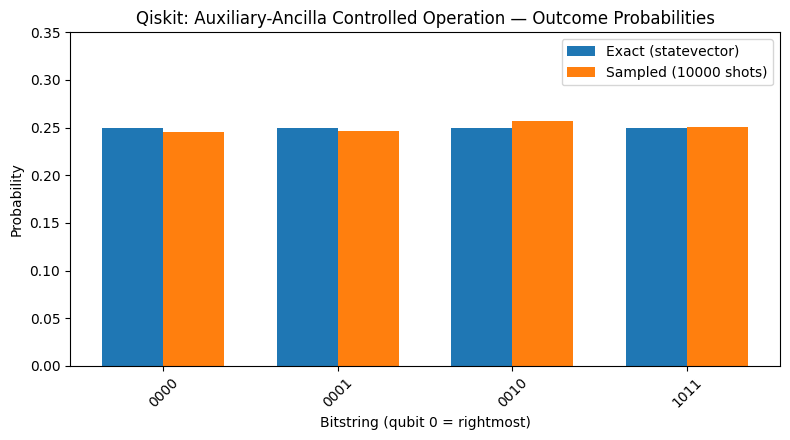

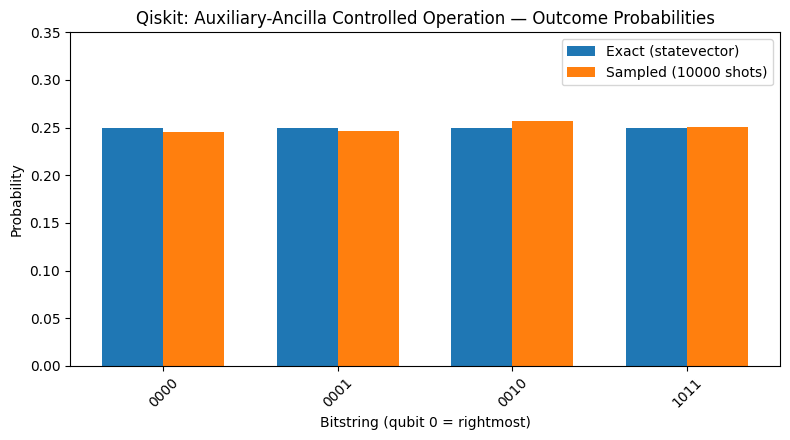

In [8]:
# Histogram (manual matplotlib bar chart, styled to match the CUDA-Q notebook exactly).
all_keys = sorted(set(prob_dict_exact.keys()) | set(probs_sampled.keys()))
exact_vals = [prob_dict_exact.get(k, 0.0) for k in all_keys]
sampled_vals = [probs_sampled.get(k, 0.0) for k in all_keys]

x = np.arange(len(all_keys))
width = 0.35

fig2, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, exact_vals, width, label="Exact (statevector)", color="#1f77b4")
ax.bar(x + width / 2, sampled_vals, width, label=f"Sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(all_keys, rotation=45)
ax.set_ylim(0, 0.35)
ax.set_xlabel("Bitstring (qubit 0 = rightmost)")
ax.set_ylabel("Probability")
ax.set_title("Qiskit: Auxiliary-Ancilla Controlled Operation — Outcome Probabilities")
ax.legend()
fig2.tight_layout()
fig2.savefig("aux_ops_ccx_ancilla_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig2


In [9]:
# Resource counts.
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))
print("Number of qubits used as auxiliary/ancilla:", 1, "-> qubit index", Q2_ANCILLA)


Circuit depth: 4
Gate counts: {'h': 2, 'ccx': 2, 'cx': 1}
Number of qubits used as auxiliary/ancilla: 1 -> qubit index 2


### Convention notes (plain text, restated)

- **Bit ordering:** qubit 0 = rightmost character of every bitstring in this notebook.
  This is Qiskit's native convention, so **no reversal was applied**.
- **Global phase:** vector rotated so the first nonzero amplitude in ascending-bitstring
  order is real & positive. Here that amplitude was already real & positive (no-op).
- **Ancilla contract:** qubit `q2` is guaranteed to return to `|0>` at the end of the
  circuit for every input on `q0, q1` — verified numerically above (only bitstrings with
  the `q2` bit at position 2 (0-indexed from the right) equal to `0` appear with nonzero
  probability).


In [10]:
# Final result dict — the EXACT (noise-free) statevector-derived probabilities.
# This is what gets diffed against CUDAQ_RESULT (shot noise on the sampled counts could
# easily exceed the 1e-3 tolerance at 10000 shots, so the diff-check uses the exact values).
QISKIT_RESULT = prob_dict_exact
print("QISKIT_RESULT =", QISKIT_RESULT)

# For reference only (not used in the cross-notebook diff-check):
QISKIT_MEASURED_RESULT = {k: round(v, 4) for k, v in probs_sampled.items() if v > 0}
print("QISKIT_MEASURED_RESULT (10000-shot sampled reference) =", QISKIT_MEASURED_RESULT)


QISKIT_RESULT = {'0000': 0.25, '0001': 0.25, '0010': 0.25, '1011': 0.25}
QISKIT_MEASURED_RESULT (10000-shot sampled reference) = {'1011': 0.2505, '0001': 0.2466, '0000': 0.2455, '0010': 0.2574}


In [11]:
# --- Cross-notebook diff-check (commented out) ---
# After running the CUDA-Q notebook, copy its printed CUDAQ_RESULT dict below, then
# uncomment this block and run it.
#
# CUDAQ_RESULT = {'0000': 0.25, '0001': 0.25, '0010': 0.25, '1011': 0.25}  # <- paste real output here
#
# hand_computed_expected = {'0000': 0.25, '0001': 0.25, '0010': 0.25, '1011': 0.25}
#
# all_keys = set(QISKIT_RESULT) | set(CUDAQ_RESULT) | set(hand_computed_expected)
# max_delta_vs_cudaq = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
# max_delta_vs_hand  = max(abs(QISKIT_RESULT.get(k, 0) - hand_computed_expected.get(k, 0)) for k in all_keys)
# print("Max |QISKIT_RESULT - CUDAQ_RESULT| =", max_delta_vs_cudaq)
# print("Max |QISKIT_RESULT - hand-computed| =", max_delta_vs_hand)
# assert max_delta_vs_cudaq < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance!"
# assert max_delta_vs_hand < 1e-3, "Qiskit result disagrees with the hand-derived expectation!"
# print("PASS: Qiskit matches both CUDA-Q and the hand-computed expectation within 1e-3.")
#
# Hand-derived expectation, worked by hand (also independently confirmed with NumPy):
# H⊗H puts (q0,q1) into an equal mixture of 00,01,10,11 (prob 1/4 each). CCX(q0,q1->q2)
# then CX(q2->q3) then CCX(q0,q1->q2) is exactly a Toffoli CCX(q0,q1->q3) with q2 always
# returned to 0. So q3 flips (to 1) only on the q0=q1=1 branch, and q2 is always 0.
# Printed bitstring = q3 q2 q1 q0 (qubit0 rightmost):
#   q0=0,q1=0 -> q3=0,q2=0 -> "0000"   (prob 0.25)
#   q0=1,q1=0 -> q3=0,q2=0 -> "0001"   (prob 0.25)
#   q0=0,q1=1 -> q3=0,q2=0 -> "0010"   (prob 0.25)
#   q0=1,q1=1 -> q3=1,q2=0 -> "1011"   (prob 0.25)
